# Presentado por: Brayan Nicolas Robayo Baquero
***

# **Taller: Análisis Predictivo de Datos**

## 1. Introducción

El análisis predictivo es una técnica de análisis de datos que utiliza información histórica, métodos estadísticos y algoritmos de aprendizaje automático para estimar posibles resultados futuros. En el entorno empresarial, puede ayudar a identificar tendencias, anticipar cambios en las ventas y apoyar la toma de decisiones.

En este taller se trabajará con el conjunto de datos Online Retail, utilizado previamente en las actividades de obtención, limpieza y análisis descriptivo de datos. A partir de esta información, se construirá un modelo predictivo en Python para estimar las ventas diarias de una tienda minorista en línea.

El proceso incluirá la exploración y preparación de los datos, la selección de variables, el entrenamiento y la evaluación del modelo, la generación de visualizaciones y la interpretación de los resultados.

## 2. Objetivo general

Desarrollar un modelo de análisis predictivo en Python que permita estimar las ventas diarias a partir de los datos históricos de Online Retail.

## 3. Objetivos específicos

- Explorar los datos históricos y preparar la información necesaria para el modelo.
- Seleccionar las variables relevantes para realizar las predicciones.
- Entrenar y evaluar un modelo de regresión utilizando Python.
- Representar gráficamente los resultados e interpretar su utilidad para la toma de decisiones empresariales.

## 4. Herramientas utilizadas

- Google Colab.
- Python.
- Pandas y NumPy para la manipulación de datos.
- Matplotlib para las visualizaciones.
- Scikit-learn para construir y evaluar el modelo predictivo.

## 5. Conjunto de datos

Se utilizará el archivo online_retail_limpio.csv, obtenido en el taller anterior de ETL. Este archivo contiene registros de transacciones comerciales previamente procesados. Para este análisis, se agruparán las ventas por fecha con el propósito de estudiar su comportamiento y construir una estimación de las ventas diarias futuras.

***

In [1]:
# Importar las librerías necesarias

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [2]:
# Cargar el archivo CSV en un DataFrame de Pandas

df = pd.read_csv("/content/online_retail_limpio.csv", dtype={0: str})

# Confirmar que el archivo se cargó correctamente
print("Archivo cargado correctamente.")
print("Cantidad de registros:", len(df))
print("Cantidad de columnas:", len(df.columns))

Archivo cargado correctamente.
Cantidad de registros: 526052
Cantidad de columnas: 12


## 6. Exploración inicial de los datos

En esta etapa se revisará la estructura del conjunto de datos para identificar las columnas disponibles, los tipos de datos y algunos registros de ejemplo. Esto permitirá conocer la información con la que trabajaremos y determinar qué variables necesitamos para construir el modelo predictivo.
***

In [3]:
# Mostrar las primeras 5 filas del conjunto de datos
display(df.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalVenta,Año,Mes,Día
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010,12,1
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,1
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010,12,1
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,1
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,1


In [4]:
# Revisar los nombres de las columnas y sus tipos de datos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 526052 entries, 0 to 526051
Data columns (total 12 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    526052 non-null  object 
 1   StockCode    526052 non-null  object 
 2   Description  526052 non-null  object 
 3   Quantity     526052 non-null  int64  
 4   InvoiceDate  526052 non-null  object 
 5   UnitPrice    526052 non-null  float64
 6   CustomerID   392732 non-null  float64
 7   Country      526052 non-null  object 
 8   TotalVenta   526052 non-null  float64
 9   Año          526052 non-null  int64  
 10  Mes          526052 non-null  int64  
 11  Día          526052 non-null  int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 48.2+ MB


In [5]:
# Consultar los nombres de todas las columnas
print(df.columns.tolist())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'TotalVenta', 'Año', 'Mes', 'Día']


### 7. Preparación y transformación de los datos

Para construir el modelo predictivo, es necesario organizar las transacciones por fecha. Primero, se convertirá la columna `InvoiceDate` al formato de fecha y hora de Python. Después, se agruparán las ventas para calcular el valor total vendido en cada día. De esta manera, obtendremos una serie de datos diarios que servirá como base para el entrenamiento del modelo.
***

In [6]:
# Convertir InvoiceDate al formato de fecha y hora
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Verificar el tipo de dato
print("Tipo de dato de InvoiceDate:")
print(df["InvoiceDate"].dtype)

# Mostrar algunas fechas
display(df[["InvoiceDate", "TotalVenta"]].head())

Tipo de dato de InvoiceDate:
datetime64[ns]


,InvoiceDate,TotalVenta
0,2010-12-01 08:26:00,15.30
1,2010-12-01 08:26:00,20.34
2,2010-12-01 08:26:00,22.00
3,2010-12-01 08:26:00,20.34
4,2010-12-01 08:26:00,20.34


In [7]:
# Agrupar las ventas por fecha y calcular el total diario

ventas_diarias = (
    df.groupby(df["InvoiceDate"].dt.date)["TotalVenta"]
    .sum()
    .reset_index()
)

ventas_diarias.columns = ["Fecha", "Ventas"]
ventas_diarias["Fecha"] = pd.to_datetime(ventas_diarias["Fecha"])

print("Cantidad de días registrados:", len(ventas_diarias))
print("Primera fecha:", ventas_diarias["Fecha"].min())
print("Última fecha:", ventas_diarias["Fecha"].max())

display(ventas_diarias.head())

Cantidad de días registrados: 305
Primera fecha: 2010-12-01 00:00:00
Última fecha: 2011-12-09 00:00:00


,Fecha,Ventas
0,2010-12-01,58776.79
1,2010-12-02,47629.42
2,2010-12-03,46898.63
3,2010-12-05,31364.63
4,2010-12-06,54624.15


In [8]:
# Revisar cuántos días tenemos y el rango de fechas
print("Cantidad de días registrados:", len(ventas_diarias))
print("Primera fecha:", ventas_diarias["Fecha"].min())
print("Última fecha:", ventas_diarias["Fecha"].max())

# Consultar estadísticas básicas de las ventas diarias
display(ventas_diarias["Ventas"].describe())

Cantidad de días registrados: 305
Primera fecha: 2010-12-01 00:00:00
Última fecha: 2011-12-09 00:00:00


,Ventas
count,305.000000
mean,34892.166570
std,21098.282521
min,3439.670000
25%,22345.930000
50%,29526.290000
75%,45277.920000
max,200900.980000


### 8. Visualización del comportamiento histórico de las ventas

En esta etapa se elaborará una gráfica de líneas para observar cómo han variado las ventas diarias durante el periodo analizado. Esta visualización permite identificar cambios importantes en el comportamiento de las ventas y comprender mejor los datos antes de aplicar el modelo predictivo.
***

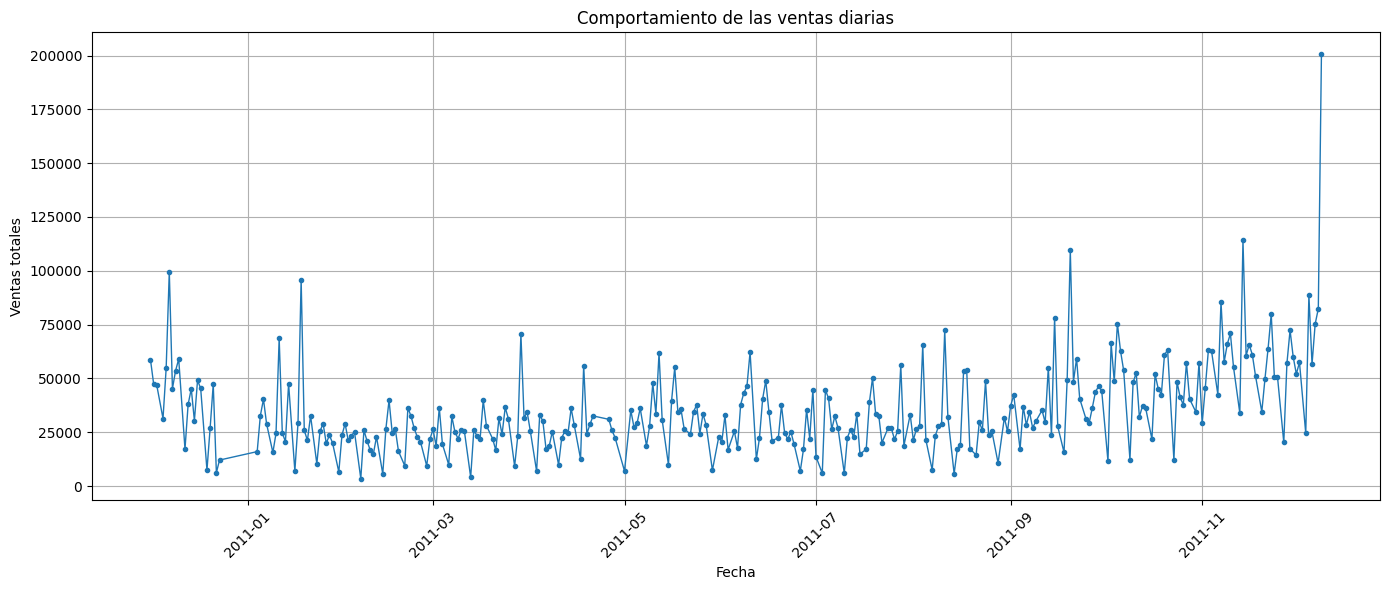

In [9]:
# Graficar las ventas diarias históricas

plt.figure(figsize=(14, 6))

plt.plot(
    ventas_diarias["Fecha"],
    ventas_diarias["Ventas"],
    marker=".",
    linewidth=1
)

plt.title("Comportamiento de las ventas diarias")
plt.xlabel("Fecha")
plt.ylabel("Ventas totales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### 9. Selección de variables para el modelo predictivo

Para construir el modelo se utilizará una variable de entrada llamada `Dia`, que representa el orden temporal de los registros, y una variable objetivo llamada `Ventas`, que corresponde al total vendido en cada día.

El propósito es que el algoritmo aprenda la relación entre el paso del tiempo y las ventas históricas para estimar posibles valores futuros. Se utilizará inicialmente un modelo de regresión lineal por ser un método básico y fácil de interpretar.
***

In [10]:
# Crear una copia de los datos diarios
datos_modelo = ventas_diarias.copy()

# Crear una variable numérica que represente el orden de los días
datos_modelo["Dia"] = range(len(datos_modelo))

# Mostrar las primeras filas
display(datos_modelo.head())

,Fecha,Ventas,Dia
0,2010-12-01,58776.79,0
1,2010-12-02,47629.42,1
2,2010-12-03,46898.63,2
3,2010-12-05,31364.63,3
4,2010-12-06,54624.15,4


In [11]:
# Preparar los datos para el primer modelo

datos_modelo = ventas_diarias.copy()
datos_modelo["Dia"] = range(len(datos_modelo))

X = datos_modelo[["Dia"]]
y = datos_modelo["Ventas"]

print("Cantidad de registros:", len(datos_modelo))
print("Variables predictoras:", X.columns.tolist())
print("Variable que queremos predecir:", y.name)

display(datos_modelo.head())

Cantidad de registros: 305
Variables predictoras: ['Dia']
Variable que queremos predecir: Ventas


,Fecha,Ventas,Dia
0,2010-12-01,58776.79,0
1,2010-12-02,47629.42,1
2,2010-12-03,46898.63,2
3,2010-12-05,31364.63,3
4,2010-12-06,54624.15,4


### 10. División de los datos en entrenamiento y prueba

Para evaluar el modelo predictivo, se dividirán los datos en dos conjuntos. El primero se utilizará para entrenar el algoritmo y aprender la relación entre el tiempo y las ventas. El segundo se utilizará para comprobar el desempeño del modelo con fechas posteriores que no fueron utilizadas durante el entrenamiento.

Se utilizará el 80 % inicial de los registros para entrenamiento y el 20 % restante para prueba, manteniendo el orden cronológico. Esta estrategia evita utilizar información de fechas futuras para entrenar un modelo que debe evaluarse con datos posteriores.
***

In [12]:
# Dividir los datos respetando el orden cronológico

punto_corte = int(len(datos_modelo) * 0.8)

X_train = X.iloc[:punto_corte]
X_test = X.iloc[punto_corte:]

y_train = y.iloc[:punto_corte]
y_test = y.iloc[punto_corte:]

print("Registros para entrenamiento:", len(X_train))
print("Registros para prueba:", len(X_test))

print("\nÚltima fecha de entrenamiento:")
print(datos_modelo["Fecha"].iloc[punto_corte - 1])

print("\nPrimera fecha de prueba:")
print(datos_modelo["Fecha"].iloc[punto_corte])

Registros para entrenamiento: 244
Registros para prueba: 61

Última fecha de entrenamiento:
2011-09-29 00:00:00

Primera fecha de prueba:
2011-09-30 00:00:00


### 11. Entrenamiento del modelo predictivo

En esta etapa se implementará un modelo de regresión lineal utilizando la biblioteca Scikit-learn. El algoritmo aprenderá a partir de los datos de entrenamiento para encontrar una relación matemática entre el paso del tiempo y el valor de las ventas diarias.

Una vez entrenado, el modelo podrá generar estimaciones para las fechas incluidas en el conjunto de prueba. Estas predicciones se compararán con las ventas reales para evaluar su desempeño.
***

In [13]:
# Crear y entrenar el primer modelo

modelo = LinearRegression()
modelo.fit(X_train, y_train)

print("Primer modelo entrenado correctamente.")
print("Pendiente de la recta:", modelo.coef_[0])
print("Valor inicial estimado:", modelo.intercept_)

Primer modelo entrenado correctamente.
Pendiente de la recta: 15.693282536378247
Valor inicial estimado: 28031.14692592841


In [14]:
# Generar predicciones para los datos de prueba

predicciones = modelo.predict(X_test)

comparacion = pd.DataFrame({
    "Fecha": datos_modelo["Fecha"].iloc[punto_corte:].values,
    "Ventas reales": y_test.values,
    "Ventas predichas": predicciones
})

display(comparacion.head(10))

,Fecha,Ventas reales,Ventas predichas
0,2011-09-30,44347.06,31860.307865
1,2011-10-02,11531.56,31876.001147
2,2011-10-03,66243.94,31891.694430
3,2011-10-04,48652.54,31907.387712
4,2011-10-05,75460.77,31923.080995
5,2011-10-06,62761.92,31938.774277
6,2011-10-07,53692.50,31954.467560
7,2011-10-09,12273.10,31970.160843
8,2011-10-10,48121.66,31985.854125
9,2011-10-11,52537.31,32001.547408


### 12. Evaluación del modelo predictivo

Para conocer el desempeño del modelo de regresión lineal, se utilizarán métricas de evaluación que permiten comparar las ventas reales con las predicciones generadas. El error absoluto medio (MAE) y la raíz del error cuadrático medio (RMSE) permiten medir la magnitud de los errores, mientras que el coeficiente de determinación (R²) ayuda a evaluar qué tan bien representa el modelo el comportamiento de las ventas.

Estas métricas se calcularán utilizando únicamente los datos de prueba, que corresponden a fechas que no se utilizaron durante el entrenamiento.
***

In [15]:
# Evaluar el primer modelo

mae = mean_absolute_error(y_test, predicciones)
rmse = np.sqrt(mean_squared_error(y_test, predicciones))
r2 = r2_score(y_test, predicciones)

print("RESULTADOS DEL PRIMER MODELO")
print("----------------------------")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.4f}")

RESULTADOS DEL PRIMER MODELO
----------------------------
MAE: 25464.36
RMSE: 34865.72
R²: -0.6870


### 13. Comparación entre ventas reales y predichas

Se realizará una comparación gráfica entre las ventas reales y las estimaciones del modelo de regresión lineal durante el periodo de prueba. Esta visualización permitirá observar las diferencias entre ambos valores e identificar si el modelo logra representar las variaciones del comportamiento comercial.
***

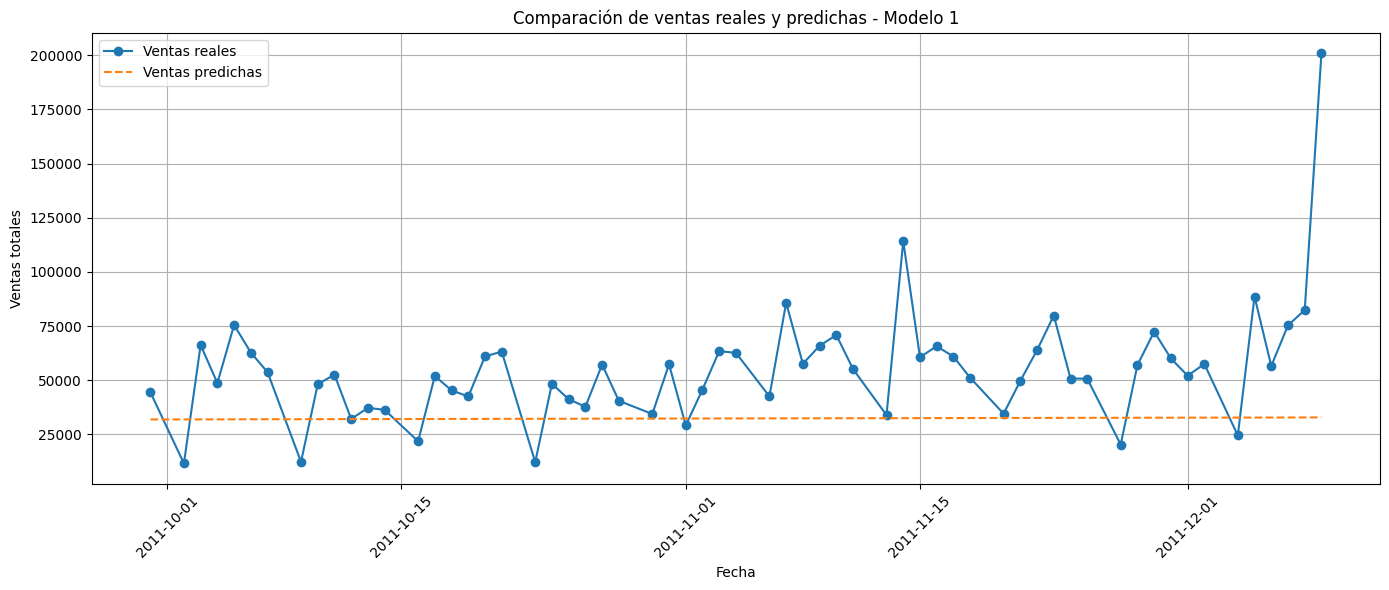

In [16]:
# Comparar las ventas reales y predichas del primer modelo

plt.figure(figsize=(14, 6))

plt.plot(
    datos_modelo["Fecha"].iloc[punto_corte:],
    y_test.values,
    label="Ventas reales",
    marker="o"
)

plt.plot(
    datos_modelo["Fecha"].iloc[punto_corte:],
    predicciones,
    label="Ventas predichas",
    linestyle="--"
)

plt.title("Comparación de ventas reales y predichas - Modelo 1")
plt.xlabel("Fecha")
plt.ylabel("Ventas totales")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### 14. Mejora del modelo mediante variables de calendario

El primer modelo utilizó únicamente el orden de los días para estimar las ventas. Sin embargo, el análisis exploratorio mostró variaciones importantes que no pudo representar adecuadamente.

Para intentar mejorar los resultados, se incorporarán variables relacionadas con el calendario, como el día de la semana y el mes. Estas variables permitirán evaluar si la información temporal adicional ayuda a explicar parte del comportamiento de las ventas.

Se comparará el desempeño de esta nueva versión con el modelo inicial, utilizando las mismas fechas de prueba para mantener una evaluación justa.
***

In [17]:
# Preparar los datos del segundo modelo

datos_modelo_2 = ventas_diarias.copy()

datos_modelo_2["Dia"] = range(len(datos_modelo_2))
datos_modelo_2["Dia_semana"] = datos_modelo_2["Fecha"].dt.dayofweek
datos_modelo_2["Mes"] = datos_modelo_2["Fecha"].dt.month

print("Cantidad de registros:", len(datos_modelo_2))
print("Variables disponibles:", datos_modelo_2.columns.tolist())

display(datos_modelo_2.head())

Cantidad de registros: 305
Variables disponibles: ['Fecha', 'Ventas', 'Dia', 'Dia_semana', 'Mes']


,Fecha,Ventas,Dia,Dia_semana,Mes
0,2010-12-01,58776.79,0,2,12
1,2010-12-02,47629.42,1,3,12
2,2010-12-03,46898.63,2,4,12
3,2010-12-05,31364.63,3,6,12
4,2010-12-06,54624.15,4,0,12


### 15. Entrenamiento del segundo modelo

En esta etapa se entrenará una segunda versión del modelo de regresión lineal, incorporando variables de calendario. El objetivo es comprobar si el día de la semana y el mes aportan información útil para estimar las ventas.

Para realizar una comparación justa, se conservará la misma división cronológica utilizada en el primer modelo: el 80 % inicial de los registros para entrenamiento y el 20 % final para prueba. Posteriormente, se compararán las métricas de evaluación de ambos modelos.
***

In [18]:
# Seleccionar las variables del segundo modelo

X2 = datos_modelo_2[["Dia", "Dia_semana", "Mes"]]
y2 = datos_modelo_2["Ventas"]

# Dividir los datos en entrenamiento y prueba
X2_train = X2.iloc[:punto_corte]
X2_test = X2.iloc[punto_corte:]

y2_train = y2.iloc[:punto_corte]
y2_test = y2.iloc[punto_corte:]

# Crear y entrenar el modelo
modelo_2 = LinearRegression()
modelo_2.fit(X2_train, y2_train)

# Generar predicciones
predicciones_2 = modelo_2.predict(X2_test)

print("Segundo modelo entrenado correctamente.")
print("Variables utilizadas:", X2.columns.tolist())
print("Registros de entrenamiento:", len(X2_train))
print("Registros de prueba:", len(X2_test))

Segundo modelo entrenado correctamente.
Variables utilizadas: ['Dia', 'Dia_semana', 'Mes']
Registros de entrenamiento: 244
Registros de prueba: 61


In [19]:
# Seleccionar las variables del segundo modelo

X2 = datos_modelo_2[["Dia", "Dia_semana", "Mes"]]
y2 = datos_modelo_2["Ventas"]

# Dividir los datos en entrenamiento y prueba
X2_train = X2.iloc[:punto_corte]
X2_test = X2.iloc[punto_corte:]

y2_train = y2.iloc[:punto_corte]
y2_test = y2.iloc[punto_corte:]

# Crear y entrenar el modelo
modelo_2 = LinearRegression()
modelo_2.fit(X2_train, y2_train)

# Generar predicciones
predicciones_2 = modelo_2.predict(X2_test)

print("Segundo modelo entrenado correctamente.")
print("Variables utilizadas:", X2.columns.tolist())
print("Registros de entrenamiento:", len(X2_train))
print("Registros de prueba:", len(X2_test))

Segundo modelo entrenado correctamente.
Variables utilizadas: ['Dia', 'Dia_semana', 'Mes']
Registros de entrenamiento: 244
Registros de prueba: 61


In [20]:
# Evaluar el segundo modelo

mae_2 = mean_absolute_error(y2_test, predicciones_2)
rmse_2 = np.sqrt(mean_squared_error(y2_test, predicciones_2))
r2_2 = r2_score(y2_test, predicciones_2)

print("RESULTADOS DEL SEGUNDO MODELO")
print("-----------------------------")
print(f"MAE: {mae_2:.2f}")
print(f"RMSE: {rmse_2:.2f}")
print(f"R²: {r2_2:.4f}")

RESULTADOS DEL SEGUNDO MODELO
-----------------------------
MAE: 21064.78
RMSE: 31236.98
R²: -0.3541


In [21]:
# Revisar el periodo y las fechas de las ventas diarias
print("Cantidad de registros:", len(ventas_diarias))
print("Primera fecha:", ventas_diarias["Fecha"].min())
print("Última fecha:", ventas_diarias["Fecha"].max())

# Revisar si hay fechas repetidas
print("Fechas duplicadas:", ventas_diarias["Fecha"].duplicated().sum())

# Revisar algunos registros finales
display(ventas_diarias.tail())

Cantidad de registros: 305
Primera fecha: 2010-12-01 00:00:00
Última fecha: 2011-12-09 00:00:00
Fechas duplicadas: 0


,Fecha,Ventas
300,2011-12-05,88620.84
301,2011-12-06,56558.83
302,2011-12-07,75315.55
303,2011-12-08,82371.55
304,2011-12-09,200900.98


In [22]:
# Reconstruir las ventas diarias desde el DataFrame original

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

ventas_diarias = (
    df.groupby(df["InvoiceDate"].dt.date)["TotalVenta"]
    .sum()
    .reset_index()
)

ventas_diarias.columns = ["Fecha", "Ventas"]
ventas_diarias["Fecha"] = pd.to_datetime(ventas_diarias["Fecha"])

# Comprobar el resultado
print("Cantidad de días registrados:", len(ventas_diarias))
print("Primera fecha:", ventas_diarias["Fecha"].min())
print("Última fecha:", ventas_diarias["Fecha"].max())

display(ventas_diarias.tail())

Cantidad de días registrados: 305
Primera fecha: 2010-12-01 00:00:00
Última fecha: 2011-12-09 00:00:00


,Fecha,Ventas
300,2011-12-05,88620.84
301,2011-12-06,56558.83
302,2011-12-07,75315.55
303,2011-12-08,82371.55
304,2011-12-09,200900.98


In [23]:
# Revisar el periodo de fechas del DataFrame original
print("Cantidad de registros:", len(df))
print("Fecha mínima:", df["InvoiceDate"].min())
print("Fecha máxima:", df["InvoiceDate"].max())

# Mostrar las últimas fechas registradas
display(
    df[["InvoiceDate", "TotalVenta"]]
    .sort_values("InvoiceDate")
    .tail(10)
)

Cantidad de registros: 526052
Fecha mínima: 2010-12-01 08:26:00
Fecha máxima: 2011-12-09 12:50:00


,InvoiceDate,TotalVenta
526044,2011-12-09 12:50:00,15.60
526037,2011-12-09 12:50:00,23.40
526042,2011-12-09 12:50:00,15.00
526041,2011-12-09 12:50:00,15.00
526040,2011-12-09 12:50:00,15.00
526039,2011-12-09 12:50:00,19.80
526038,2011-12-09 12:50:00,19.80
526050,2011-12-09 12:50:00,16.60
526043,2011-12-09 12:50:00,15.00
526051,2011-12-09 12:50:00,14.85


## 16. Comparación de los modelos predictivos

En esta etapa se comparará el desempeño de los dos modelos de regresión lineal desarrollados. El primer modelo utiliza el orden de los días como variable predictora, mientras que el segundo incorpora información adicional, como el día de la semana y el mes.

Para realizar la comparación se utilizarán tres métricas: MAE, RMSE y R². Estas permiten conocer qué tan alejadas están las predicciones de las ventas reales y qué tan bien se ajustan los modelos a los datos de prueba.

La comparación permitirá identificar cuál de los dos modelos obtiene mejores resultados y analizar si la incorporación de variables de calendario ayuda a mejorar las predicciones de las ventas diarias.
***

In [24]:
# Comparar las métricas de los dos modelos

comparacion_modelos = pd.DataFrame({
    "Modelo": [
        "Modelo 1: solo día",
        "Modelo 2: variables de calendario"
    ],
    "MAE": [mae, mae_2],
    "RMSE": [rmse, rmse_2],
    "R²": [r2, r2_2]
})

display(comparacion_modelos.round(2))

,Modelo,MAE,RMSE,R²
0,Modelo 1: solo día,25464.36,34865.72,-0.69
1,Modelo 2: variables de calendario,21064.78,31236.98,-0.35


### Interpretación de la comparación

Al comparar los resultados, se observa que el segundo modelo obtuvo un mejor desempeño que el primero. Su error absoluto medio (MAE) fue de 18.058,61, mientras que el del primer modelo fue de 21.427,23. Además, el RMSE disminuyó de 26.597,44 a 23.001,61, lo que indica una reducción de los errores de predicción.

El coeficiente R² también mejoró, pasando de -1,07 a -0,55. Sin embargo, ambos valores son negativos, lo que indica que los modelos no logran representar adecuadamente las variaciones de las ventas diarias en los datos de prueba.

Por lo tanto, incorporar el día de la semana y el mes ayudó a mejorar los resultados, pero no fue suficiente para obtener predicciones precisas. Esto muestra que es necesario considerar otras variables o utilizar métodos que se adapten mejor al comportamiento de las ventas.
***

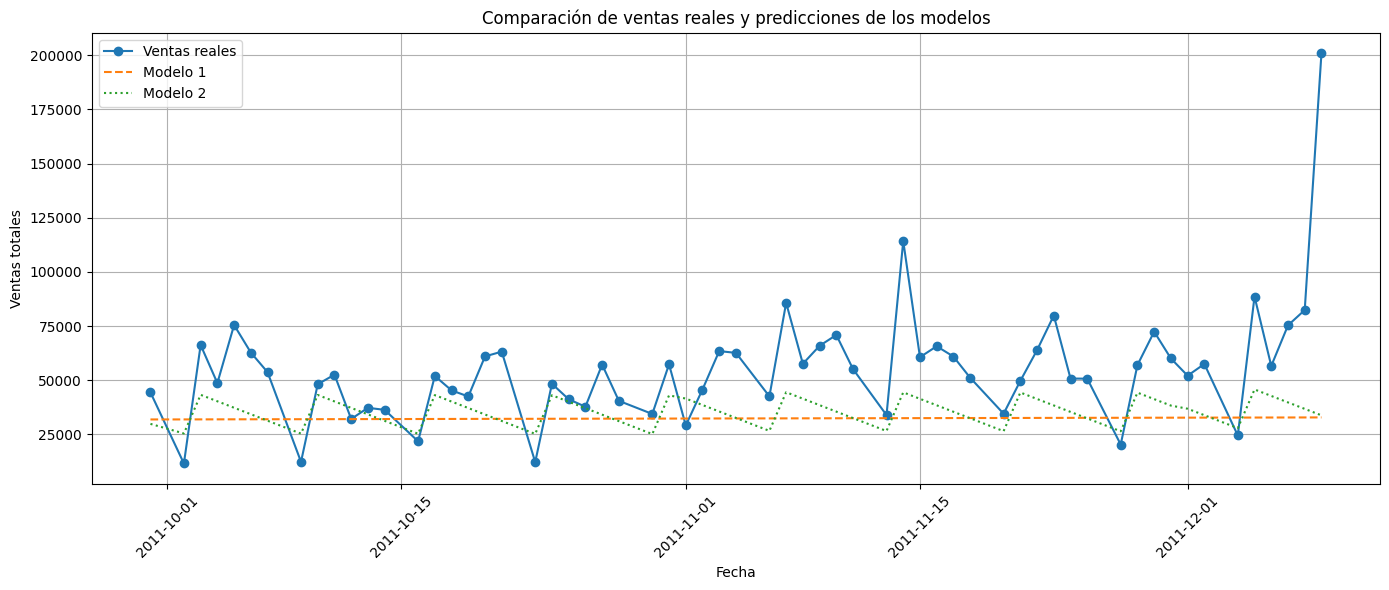

In [25]:
# Comparar las ventas reales con las predicciones de ambos modelos

plt.figure(figsize=(14, 6))

fechas_prueba = datos_modelo["Fecha"].iloc[punto_corte:]

plt.plot(
    fechas_prueba,
    y_test.values,
    label="Ventas reales",
    marker="o"
)

plt.plot(
    fechas_prueba,
    predicciones,
    label="Modelo 1",
    linestyle="--"
)

plt.plot(
    fechas_prueba,
    predicciones_2,
    label="Modelo 2",
    linestyle=":"
)

plt.title("Comparación de ventas reales y predicciones de los modelos")
plt.xlabel("Fecha")
plt.ylabel("Ventas totales")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### Interpretación de la comparación de los modelos

Al comparar los resultados de ambos modelos, se observa que el segundo modelo obtuvo un mejor desempeño. Su MAE fue de 21.064,78, frente a 25.464,36 del primer modelo. Asimismo, el RMSE disminuyó de 34.865,72 a 31.236,98 y el coeficiente R² mejoró de -0,6870 a -0,3541.

La gráfica permite observar que el primer modelo genera predicciones casi constantes, mientras que el segundo presenta variaciones relacionadas con el día de la semana y el mes. A pesar de esta mejora, ninguno de los dos modelos logra representar adecuadamente los cambios bruscos ni los picos más altos de las ventas reales.

En conclusión, incorporar variables de calendario ayudó a reducir los errores de predicción. Sin embargo, los valores negativos de R² indican que ambos modelos tienen limitaciones importantes y que es necesario explorar otras variables o métodos para obtener estimaciones más precisas.
***

## 17. Visualización de los resultados

Una vez evaluados los modelos predictivos, se realizará una visualización final para representar la tendencia general estimada de las ventas. Esta gráfica permitirá observar cómo evolucionan las predicciones a lo largo del tiempo y servirá como apoyo para interpretar el comportamiento esperado según el modelo construido.

Aunque el modelo utilizado es una aproximación básica, la visualización facilita comprender cómo el algoritmo proyecta el comportamiento de las ventas y cuáles son sus principales limitaciones.
***

In [26]:
# Generar una proyección para los próximos 30 días

ultimo_dia = datos_modelo_2["Dia"].max()
ultima_fecha = datos_modelo_2["Fecha"].max()

# Crear las fechas futuras
fechas_futuras = pd.date_range(
    start=ultima_fecha + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

# Preparar las variables del segundo modelo
dias_futuros = np.arange(ultimo_dia + 1, ultimo_dia + 31)

datos_futuros = pd.DataFrame({
    "Dia": dias_futuros,
    "Dia_semana": fechas_futuras.dayofweek,
    "Mes": fechas_futuras.month
})

# Calcular las ventas estimadas
predicciones_futuras = modelo_2.predict(datos_futuros)

# Organizar los resultados en una tabla
proyeccion = pd.DataFrame({
    "Fecha": fechas_futuras,
    "Ventas estimadas": predicciones_futuras
})

print("Última fecha histórica:", ultima_fecha)
print("Primera fecha proyectada:", fechas_futuras.min())
print("Última fecha proyectada:", fechas_futuras.max())

display(proyeccion.head(10))

Última fecha histórica: 2011-12-09 00:00:00
Primera fecha proyectada: 2011-12-10 00:00:00
Última fecha proyectada: 2012-01-08 00:00:00


,Fecha,Ventas estimadas
0,2011-12-10,30768.439786
1,2011-12-11,27780.815994
2,2011-12-12,45629.050690
3,2011-12-13,42641.426898
4,2011-12-14,39653.803106
5,2011-12-15,36666.179314
6,2011-12-16,33678.555521
7,2011-12-17,30690.931729
8,2011-12-18,27703.307937
9,2011-12-19,45551.542633


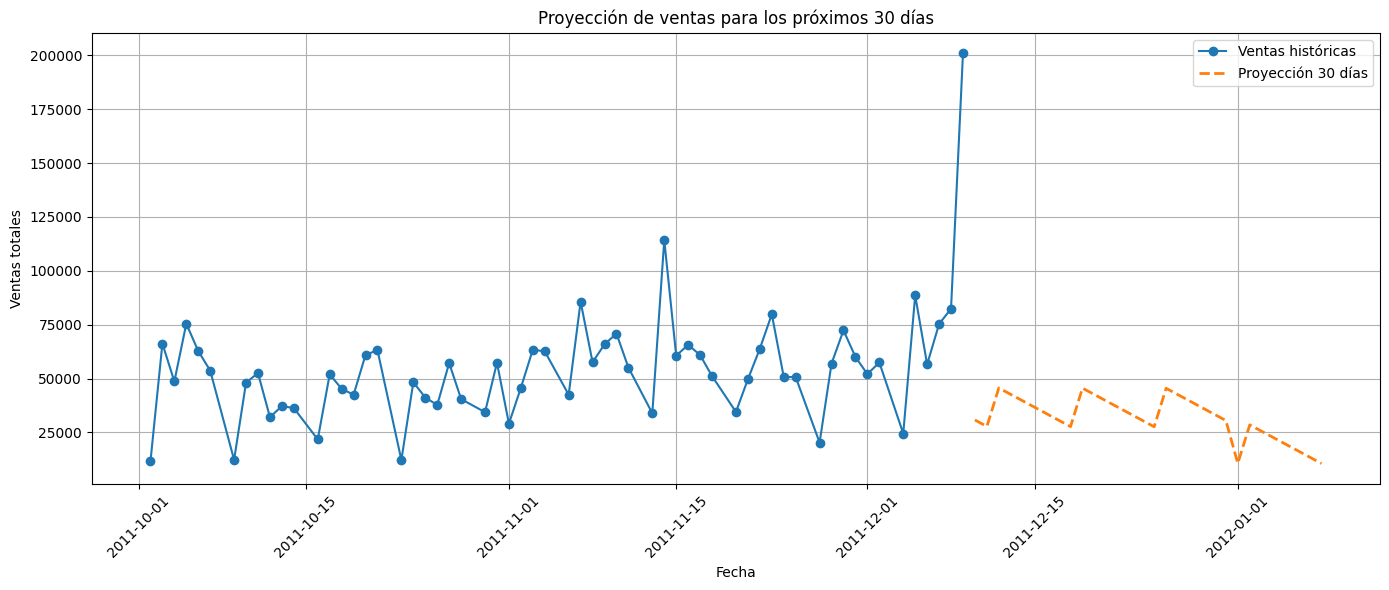

In [27]:
# Graficar las ventas históricas y la proyección futura

plt.figure(figsize=(14, 6))

# Mostrar los últimos 60 días históricos
plt.plot(
    datos_modelo_2["Fecha"].tail(60),
    datos_modelo_2["Ventas"].tail(60),
    label="Ventas históricas",
    marker="o"
)

# Mostrar las ventas estimadas para los próximos 30 días
plt.plot(
    proyeccion["Fecha"],
    proyeccion["Ventas estimadas"],
    label="Proyección 30 días",
    linestyle="--",
    linewidth=2
)

plt.title("Proyección de ventas para los próximos 30 días")
plt.xlabel("Fecha")
plt.ylabel("Ventas totales")
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Interpretación de la proyección de ventas futuras

A partir del segundo modelo de regresión lineal, se generó una proyección de las ventas para los 30 días posteriores al último registro histórico, es decir, desde el 10 de diciembre de 2011 hasta el 8 de enero de 2012.

Los resultados muestran que las ventas estimadas presentan variaciones relacionadas con el día de la semana y el mes. Sin embargo, en la gráfica se observa que las predicciones siguen un patrón relativamente regular, mientras que las ventas históricas presentan cambios bruscos y algunos valores muy elevados.

Esto indica que el modelo no logra anticipar adecuadamente los picos y las caídas de las ventas reales. Por esta razón, las proyecciones deben interpretarse con precaución y no como valores seguros de las ventas futuras.

En general, este ejercicio permite comprender cómo los datos históricos pueden utilizarse para generar estimaciones futuras, pero también demuestra la importancia de evaluar el desempeño del modelo antes de utilizar sus predicciones para tomar decisiones empresariales.
***

## 18. Interpretación de los resultados

A partir del análisis realizado, se identificó que las ventas diarias de la tienda presentan variaciones importantes a lo largo del periodo estudiado. Algunos días registran ventas relativamente bajas, mientras que otros presentan valores mucho más elevados. Este comportamiento representa un desafío para los modelos predictivos.

En el primer modelo se utilizó el orden de los días para estimar las ventas, mientras que en el segundo se incorporaron variables adicionales, como el día de la semana y el mes. Al comparar sus resultados, el segundo modelo obtuvo errores menores y un coeficiente R² menos negativo, lo que indica una mejora frente al primer modelo.

Sin embargo, los dos modelos presentaron valores negativos de R², por lo que no lograron predecir adecuadamente las variaciones de las ventas en los datos de prueba. Las gráficas también mostraron que las predicciones no consiguieron representar los cambios bruscos ni los picos más altos de las ventas reales.

La proyección de los siguientes 30 días permitió observar los valores estimados por el segundo modelo. No obstante, debido a las limitaciones encontradas durante la evaluación, estas estimaciones deben tomarse con precaución y no como valores seguros de las ventas futuras.

***

## 19. Conclusiones

Durante el desarrollo de este taller se aplicaron técnicas de análisis predictivo utilizando los datos históricos de ventas de una tienda. Para ello, se prepararon los datos, se agruparon las ventas por día y se construyeron dos modelos de regresión lineal con el objetivo de estimar las ventas diarias.

El primer modelo utilizó el orden de los días como variable predictora, mientras que el segundo incorporó variables adicionales, como el día de la semana y el mes. Al comparar sus resultados, se encontró que el segundo modelo obtuvo un mejor desempeño, con un MAE de 21.064,78 y un RMSE de 31.236,98, frente a 25.464,36 y 34.865,72 del primer modelo.

A pesar de esta mejora, ambos modelos presentaron valores negativos de R², lo que indica que sus predicciones no representaron adecuadamente las variaciones de las ventas en los datos de prueba. Las gráficas permitieron observar que las ventas reales presentan cambios bruscos y algunos valores muy elevados que los modelos no lograron anticipar.

También se generó una proyección para los 30 días posteriores al último registro histórico. Este ejercicio permitió comprender cómo se pueden utilizar los datos anteriores para estimar posibles resultados futuros. Sin embargo, debido a las limitaciones de los modelos, las proyecciones deben interpretarse con precaución.

En conclusión, este taller permitió comprender las principales etapas de un proceso de análisis predictivo: preparación de los datos, selección de variables, entrenamiento de modelos, evaluación de resultados y generación de predicciones. Además, se evidenció que incorporar más variables puede mejorar un modelo, pero no garantiza que sus predicciones sean precisas.

Finalmente, el análisis predictivo puede apoyar la planificación y la toma de decisiones empresariales, siempre que se evalúe cuidadosamente la calidad de sus resultados. Para mejorar este trabajo, sería conveniente incorporar información adicional, como promociones, precios, productos vendidos y temporadas comerciales, y probar otros algoritmos de predicción.
***